In [1]:
import os
import pickle
import sys
import threading
import time

import numpy as np
import matplotlib.pyplot as plt

root_dir = os.path.abspath("..")
data_dir = os.path.join(root_dir, "data")
figs_dir = os.path.join(root_dir, "figs")
os.makedirs(data_dir, exist_ok=True)
if root_dir not in sys.path:
    sys.path.append(root_dir)

from current_setpoints.models.machines import ieee_machine2_trained_neural_flux_and_torque
from current_setpoints.models.forward_model import ForwardModel, Fault, count_peaks_at_limit
from current_setpoints.optimization import (
    StaticOptimizer,
    ActiveSetOptimizer,
    FeasibilityOptimizer,
    calculate_grid,
    grid_to_data,
)
from current_setpoints.utils.plotting import plot_grid_segments


def call_with_timeout(timeout, fn, *args, **kwargs):
    """Same mechanism as grid.py's own _call_with_timeout (plain daemon thread, not
    ThreadPoolExecutor -- see that function's docstring for why: an executor's worker
    threads are tracked by concurrent.futures.thread's own atexit handler, which blocks
    interpreter/kernel shutdown until every such thread finishes, even abandoned ones).
    Duplicated locally rather than importing grid.py's private helper, matching how every
    other sweep notebook this session keeps its own copy."""
    result = {}

    def _run():
        try:
            result["value"] = fn(*args, **kwargs)
        except Exception as exc:
            result["error"] = exc

    t = threading.Thread(target=_run, daemon=True)
    t.start()
    t.join(timeout)
    if t.is_alive():
        return None, "timeout"
    if "error" in result:
        return None, f"exception: {result['error']!r}"
    return result.get("value"), None

In [2]:
CURR_MAX = 30.0
VOLT_MAX = 13.0
OMEGA_MAX = 1800.0  # mechanical RPM

SLSQP_OPTS = {"disp": False, "ftol": 1e-8, "maxiter": 500}
N_GRID = 60  # 2026-10-05: voltage between nodes overshoots ~0.2% at 60 nodes vs ~0.9% at 30; 60 nodes
             # converge since the joint solve uses exact torque gradients + per-unit scaling

N_TORQ = 21  # full sweep, 60 nodes: ~2.5-4 h estimated (2026-10-05)
N_OMEGA = 21
# Torque targets per speed, as fractions of the higher of the two optimizers' max torques there
# (see the probing cell): coarse from 0 up to COARSE_TOP, then uniformly fine from COARSE_TOP up
# to TORQ_TOP, where both maxima and the field-weakening behaviour lie. At 25 points: 9 points
# every 10 % up to 0.8, then 16 points every ~1.4 % up to 1.02. TORQ_TOP slightly above 1 keeps
# both ceilings inside the sampled range.
COARSE_TOP = 0.8
TORQ_TOP = 1.02
PROBE_TIMEOUT_SECONDS = 900  # a 60-node dynamic max-torque probe took up to 360 s (1500 rpm)
CELL_TIMEOUT_SECONDS = 900  # hard per-solve cap, see grid.py's _call_with_timeout -- also caps
                            # calculate_grid's own per-speed max-torque probe

drive = ieee_machine2_trained_neural_flux_and_torque(curr_max=CURR_MAX, volt_max=VOLT_MAX)
fwd = ForwardModel(drive, n_theta=700, fault=Fault(()))  # healthy mode only, per request
const_mech_speed = 30.0 / (np.pi * drive.n_ppairs)
dim = drive.dim

optimizer_static = StaticOptimizer(fwd, opts=SLSQP_OPTS)
optimizer_dynamic_old = ActiveSetOptimizer(fwd, opts=SLSQP_OPTS, n_grid=N_GRID)
optimizer_dynamic_new = FeasibilityOptimizer(fwd, opts=SLSQP_OPTS, n_grid=N_GRID)  # deferred, see its own cell

# Grid size and node count in the folder/file names: the plot callback skips PNGs that already
# exist and cells 4-5 load a cached map if one exists, so runs with other settings must not share them.
run_tag = f"{N_TORQ}x{N_OMEGA}_N{N_GRID}"
png_dir_static = os.path.join(figs_dir, f"map_static_neural_flux_torque_{run_tag}")
png_dir_dynamic_old = os.path.join(figs_dir, f"map_dynamic_neural_flux_torque_{run_tag}")
os.makedirs(png_dir_static, exist_ok=True)
os.makedirs(png_dir_dynamic_old, exist_ok=True)

print(f"healthy mode, neural flux + neural torque, N_GRID={N_GRID}, grid {N_TORQ}x{N_OMEGA}")

healthy mode, neural flux + neural torque, N_GRID=60, grid 21x21


In [3]:
# Shared per-row torque targets, non-uniform (dense near each row's own ceiling), IDENTICAL
# for both optimizers at a given row -- required so a cell-by-cell diff between the two maps
# stays valid (see chat: warping each optimizer's axis around its OWN local ceiling separately
# would put different absolute torque values at "the same" grid index). Each optimizer still
# gets its OWN warm-start guess (its own max-torque-achieving current at that speed), just the
# same TARGET torque values.
def _representative_dq(curr_dq):
    # StaticOptimizer.maximize_torque returns a single (dim,) vector; dynamic-mode optimizers
    # (ActiveSetOptimizer/FeasibilityOptimizer) return the FULL per-node trajectory (n_grid,
    # dim) since their own achievable-torque ceiling is a whole-trajectory quantity -- reduce
    # to one representative vector for use as a per-row warm-start seed, matching exactly how
    # grid.py's own _fill_grid_point reduces a trajectory to curr_dq_grid (np.nanmean).
    return curr_dq if curr_dq.ndim == 1 else np.nanmean(curr_dq, axis=0)


vec_omega = np.linspace(0.0, OMEGA_MAX / const_mech_speed, N_OMEGA)

tmax_static_row = np.full(N_OMEGA, np.nan)
tmax_old_row = np.full(N_OMEGA, np.nan)
curr_at_tmax_static = np.full((dim, N_OMEGA), np.nan)
curr_at_tmax_old = np.full((dim, N_OMEGA), np.nan)

t0 = time.perf_counter()
prev_margin = 1.0  # carried across speeds -- neighboring rows tend to need a similar backoff
                    # fraction, so starting the search there (instead of always at 1.0) skips
                    # margins already known to fail (see maximize_torque's start_margin doc)
for idx_omega, omega in enumerate(vec_omega):
    omega = float(omega)
    sol_s, err_s = call_with_timeout(PROBE_TIMEOUT_SECONDS, optimizer_static.maximize_torque, omega)
    if sol_s is not None and sol_s.success:
        tmax_static_row[idx_omega] = sol_s.torque
        curr_at_tmax_static[:, idx_omega] = _representative_dq(sol_s.curr_dq)

    # Real, verified probe -- calls the library's OWN maximize_torque (backoff search over the
    # correctly re-linearized minimize_current), not a fast unverified approximation. Only 32
    # calls total (one per row), so the added cost here is bounded (tens of minutes, not the
    # hours a per-CELL verification would cost across the full 32x32 grid).
    sol_o, err_o = call_with_timeout(
        PROBE_TIMEOUT_SECONDS, optimizer_dynamic_old.maximize_torque, omega, None, prev_margin
    )
    if sol_o is not None and sol_o.success:
        tmax_old_row[idx_omega] = sol_o.torque
        curr_at_tmax_old[:, idx_omega] = _representative_dq(sol_o.curr_dq)
        prev_margin = sol_o.diagnostics.get("margin", prev_margin)

    print(f"  probe {idx_omega + 1}/{N_OMEGA}: {omega * const_mech_speed:.1f} RPM  "
          f"static={tmax_static_row[idx_omega]:.3f}  dynamic={tmax_old_row[idx_omega]:.3f}  "
          f"(margin={prev_margin:.2f})")

print(f"probing done in {time.perf_counter() - t0:.0f}s")

# A row where a SPECIFIC optimizer's own probe failed still needs a usable (non-NaN) warm-start
# guess for that optimizer -- fall back to a generic seed there rather than leaving NaN (which
# would incorrectly skip every torque target at that row for calculate_grid's "recalculated"
# mode). shared_ref uses nanmax so one optimizer's failed probe doesn't kill the whole row's
# target for the OTHER optimizer.
seed0 = drive.seeds()[0]
nan_cols_static = ~np.isfinite(tmax_static_row)
nan_cols_old = ~np.isfinite(tmax_old_row)
curr_at_tmax_static[:, nan_cols_static] = seed0[:, None]
curr_at_tmax_old[:, nan_cols_old] = seed0[:, None]

shared_ref = np.nanmax(np.stack([tmax_static_row, tmax_old_row]), axis=0)  # higher of the two max torques
shared_ref = np.nan_to_num(shared_ref, nan=0.0)

n_coarse = max(2, round(N_TORQ * 9 / 25))  # 9 of 25 coarse points (scaled for other N_TORQ)
n_fine = N_TORQ - n_coarse
frac = np.concatenate([
    np.linspace(0.0, COARSE_TOP, n_coarse),  # coarse: 0 ... COARSE_TOP
    COARSE_TOP + (TORQ_TOP - COARSE_TOP) * np.arange(1, n_fine + 1) / n_fine,  # fine: ... TORQ_TOP
])
grid_torq_neural = np.outer(frac, shared_ref)  # (N_TORQ, N_OMEGA), shared by both optimizers

guess_static = np.broadcast_to(curr_at_tmax_static[:, None, :], (dim, N_TORQ, N_OMEGA)).copy()
guess_old = np.broadcast_to(curr_at_tmax_old[:, None, :], (dim, N_TORQ, N_OMEGA)).copy()

vec_torq_placeholder = frac * float(np.nanmax(shared_ref))  # cosmetic default label only --
                                                             # actual per-cell targets are 2D (grid_torq_neural)

dict_grid_corr_static = {
    "vec_torq": vec_torq_placeholder, "vec_omega": vec_omega,
    "grid_torq_neural": grid_torq_neural, "curr_dq_grid": guess_static,
}
dict_grid_corr_old = {
    "vec_torq": vec_torq_placeholder, "vec_omega": vec_omega,
    "grid_torq_neural": grid_torq_neural, "curr_dq_grid": guess_old,
}

  probe 1/21: 0.0 RPM  static=7.975  dynamic=8.172  (margin=1.00)
  probe 2/21: 90.0 RPM  static=7.936  dynamic=8.141  (margin=1.00)
  probe 3/21: 180.0 RPM  static=7.903  dynamic=8.118  (margin=1.00)
  probe 4/21: 270.0 RPM  static=7.875  dynamic=8.100  (margin=1.00)
  probe 5/21: 360.0 RPM  static=7.852  dynamic=8.084  (margin=1.00)
  probe 6/21: 450.0 RPM  static=7.830  dynamic=8.067  (margin=1.00)
  probe 7/21: 540.0 RPM  static=7.809  dynamic=8.046  (margin=1.00)
  probe 8/21: 630.0 RPM  static=7.786  dynamic=8.018  (margin=1.00)
  probe 9/21: 720.0 RPM  static=7.759  dynamic=7.966  (margin=1.00)
  probe 10/21: 810.0 RPM  static=7.729  dynamic=7.905  (margin=1.00)
  probe 11/21: 900.0 RPM  static=7.695  dynamic=7.855  (margin=1.00)
  probe 12/21: 990.0 RPM  static=7.657  dynamic=7.798  (margin=1.00)
  probe 13/21: 1080.0 RPM  static=7.612  dynamic=7.737  (margin=1.00)
  probe 14/21: 1170.0 RPM  static=7.552  dynamic=7.664  (margin=1.00)
  probe 15/21: 1260.0 RPM  static=7.472  dyn

In [4]:
PHASE_LETTERS = ["a", "b", "c", "d", "e"]


def segment_label(n_curr, n_volt):
    roman = {0: "", 1: "I", 2: "II"}
    return f"MTPA_{n_curr}" if n_volt == 0 else f"FW_{roman[n_volt]},{n_curr}"


def fine_idx_grid(fwd, theta_grid):
    n_theta = fwd.vec_theta.size - 1
    return np.round(theta_grid / (2 * np.pi) * n_theta).astype(int) % n_theta


def alpha_beta_xy(theta_grid, sched):
    c1, s1 = np.cos(theta_grid), np.sin(theta_grid)
    c3, s3 = np.cos(3 * theta_grid), np.sin(3 * theta_grid)
    id1, iq1, id3, iq3 = sched[:, 0], sched[:, 1], sched[:, 2], sched[:, 3]
    i_alpha = c1 * id1 - s1 * iq1
    i_beta = s1 * id1 + c1 * iq1
    i_x = c3 * id3 - s3 * iq3
    i_y = s3 * id3 + c3 * iq3
    return i_alpha, i_beta, i_x, i_y


def waveforms_for_plot(fwd, omega, curr_dq, n_theta_plot=360):
    """(theta_deg, sched, iph, vph, theta_v_deg) for either a constant (static, curr_dq.ndim==1)
    or per-node-trajectory (dynamic, curr_dq.ndim==2) current, on a common convention suitable
    for the 9-panel diagnostic plot. Static is swept fresh over n_theta_plot samples of the
    SAME constant vector (current doesn't change over the cycle, only its phase reconstruction
    does, since the dq->phase map itself rotates with theta); dynamic reuses each node's own
    angle/current directly.

    Dynamic voltage: PDF eq. (7) with the current running linearly between nodes, i.e. WITH the
    dynamic term (omega/dtheta) L (i_next - i_n) -- two values per node, just before theta_n (end
    of the incoming segment) and just after it (start of the outgoing one), the same voltages
    ActiveSetOptimizer limits and grid.py's _trajectory_waveforms reports. vph then has 2 columns
    per node, plotted against theta_v_deg (each node angle twice)."""
    kept = list(fwd.fault._kept)
    dynamic = curr_dq.ndim == 2
    if not dynamic:
        theta_grid = np.linspace(0.0, 2 * np.pi, n_theta_plot, endpoint=False)
        sched = np.tile(curr_dq, (n_theta_plot, 1))
        idx_grid = fine_idx_grid(fwd, theta_grid)
        n_pts = n_theta_plot
    else:
        n_pts = curr_dq.shape[0]
        theta_grid = np.linspace(0.0, 2 * np.pi, n_pts, endpoint=False)
        idx_grid = fine_idx_grid(fwd, theta_grid)
        sched = curr_dq
    coupling = omega / (2 * np.pi / n_pts)  # omega / dtheta (dynamic only)

    iph = np.full((len(kept), n_pts), np.nan)
    vph = np.full((len(kept), 2 * n_pts if dynamic else n_pts), np.nan)
    for k, ti in enumerate(idx_grid):
        i_n = sched[k]
        if not np.all(np.isfinite(i_n)):
            continue
        iph[:, k] = fwd.phase_map_at_theta(int(ti)) @ i_n
        gU, gL, bV = fwd.volt_map_at_theta(int(ti), omega, i_n)
        v_steady = gU @ i_n + bV
        if dynamic:
            i_prev, i_next = sched[(k - 1) % n_pts], sched[(k + 1) % n_pts]
            vph[:, 2 * k] = (v_steady + coupling * (gL @ (i_n - i_prev)))[kept]
            vph[:, 2 * k + 1] = (v_steady + coupling * (gL @ (i_next - i_n)))[kept]
        else:
            vph[:, k] = v_steady[kept]
    theta_deg = np.rad2deg(theta_grid)
    theta_v_deg = np.repeat(theta_deg, 2) if dynamic else theta_deg
    return theta_deg, sched, iph, vph, theta_v_deg


def classify_status(sol):
    if sol is None:
        return "TIMEOUT_OR_ERROR"
    if sol.success:
        return "FEASIBLE"
    if isinstance(sol.diagnostics, dict) and sol.diagnostics.get("fail_reason") == "R0 failed at some nodes":
        return "R0_INFEASIBLE"
    return "STUCK"


def save_grid_point_plot(fwd, omega, torque, rpm, sol, save_path):
    """9-panel diagnostic plot, same layout as pointwise_waveform_diagnostics.ipynb /
    feasibility_sweep_infeasible_healthy.ipynb (DQ setpoints, phase currents, phase voltages,
    copper-loss density, DQ norm, alphabeta current, xy current, achieved torque, spectrum).
    Handles BOTH a constant (static, sol.curr_dq.ndim==1) and per-node-trajectory (dynamic)
    current via waveforms_for_plot. Called unconditionally (even on failure/timeout) so
    infeasible points get plotted too -- matching feasibility_sweep_infeasible_healthy.ipynb's
    convention -- as long as there's at least one finite current to show."""
    status = classify_status(sol)
    curr_max, volt_max = fwd.drive.curr_max, fwd.drive.volt_max

    curr_dq = sol.curr_dq if sol is not None else None
    if curr_dq is None or not np.any(np.isfinite(curr_dq)):
        return status  # nothing finite to plot

    theta, sched, iph, vph, theta_v = waveforms_for_plot(fwd, omega, curr_dq)

    n_curr = count_peaks_at_limit(np.concatenate([iph, iph[:, :1]], axis=1), curr_max) if np.any(np.isfinite(iph)) else 0
    n_volt = count_peaks_at_limit(np.concatenate([vph, vph[:, :1]], axis=1), volt_max) if np.any(np.isfinite(vph)) else 0
    # Region labels (MTPA/FW from peak counting) are defined for a constant current only --
    # dynamic trajectories don't split into these segments, so their titles carry no label.
    seg_text = segment_label(n_curr, n_volt) if curr_dq.ndim == 1 else ""

    kept = list(fwd.fault._kept)
    letters = [PHASE_LETTERS[p] for p in kept]

    i_alpha, i_beta, i_x, i_y = alpha_beta_xy(np.deg2rad(theta), sched)
    norm_pw = np.sum(sched ** 2, axis=1)
    cu_pw = np.nansum(iph ** 2, axis=0)
    torque_pw = np.array([
        fwd.drive.torque(omega, sched[k]) if np.all(np.isfinite(sched[k])) else np.nan
        for k in range(sched.shape[0])
    ])

    have_fft = np.all(np.isfinite(iph))
    if have_fft:
        iph_fft = np.abs(np.fft.rfft(iph, axis=1)) / iph.shape[1]
        harmonics = np.arange(iph_fft.shape[1])

    status_color = {"FEASIBLE": "tab:green", "STUCK": "tab:orange",
                     "R0_INFEASIBLE": "tab:red", "TIMEOUT_OR_ERROR": "tab:red"}[status]

    fig, ax = plt.subplots(3, 3, figsize=(18, 13))
    fig.suptitle(f"[{status}] {seg_text}   T*={torque:.2f} Nm,  {rpm:.1f} RPM", fontsize=13, color=status_color)

    dq_lbl = [r"$i_{sd}^1$", r"$i_{sq}^1$", r"$i_{sd}^3$", r"$i_{sq}^3$"]
    dq_col = ["tab:blue", "tab:orange", "tab:green", "tab:red"]
    a = ax[0, 0]
    for j in range(fwd.drive.dim):
        a.plot(theta, sched[:, j], color=dq_col[j], label=dq_lbl[j])
    a.set_title("DQ setpoints"); a.set_xlabel(r"$\theta$ [deg]"); a.set_ylabel("DQ current [A]"); a.legend(fontsize=8)

    a = ax[0, 1]
    for p, lt in enumerate(letters):
        a.plot(theta, iph[p], label=f"$i_{{{lt}}}$")
    a.axhline(curr_max, color="gray", ls=":"); a.axhline(-curr_max, color="gray", ls=":")
    a.set_title("Phase currents"); a.set_xlabel(r"$\theta$ [deg]"); a.set_ylabel("phase current [A]"); a.legend(fontsize=8)

    a = ax[0, 2]
    for p, lt in enumerate(letters):
        a.plot(theta_v, vph[p], label=f"$v_{{{lt}}}$")
    a.axhline(volt_max, color="gray", ls=":"); a.axhline(-volt_max, color="gray", ls=":")
    a.set_title("Phase voltages"); a.set_xlabel(r"$\theta$ [deg]"); a.set_ylabel("phase voltage [V]"); a.legend(fontsize=8)

    a = ax[1, 0]
    a.plot(theta, cu_pw, color="tab:orange", label=f"mean={np.nanmean(cu_pw):.1f}")
    a.set_title(r"Copper-loss density $\sum_k i_k^2(\theta)$")
    a.set_xlabel(r"$\theta$ [deg]"); a.set_ylabel(r"$\sum_k i_k^2$ [A$^2$]"); a.legend(fontsize=8)

    a = ax[1, 1]
    a.plot(theta, norm_pw, color="tab:orange", label=r"$\|i_s(\theta)\|^2$")
    a.set_title(r"DQ norm $\|i_s\|^2$"); a.set_xlabel(r"$\theta$ [deg]"); a.set_ylabel(r"$\|i_s\|^2$ [A$^2$]"); a.legend(fontsize=8)

    a = ax[1, 2]
    a.plot(i_alpha, i_beta, color="tab:purple")
    a.set_title(r"$\alpha\beta$ current"); a.set_xlabel(r"$i_\alpha$ [A]"); a.set_ylabel(r"$i_\beta$ [A]"); a.set_aspect("equal")

    a = ax[2, 0]
    a.plot(i_x, i_y, color="tab:brown")
    a.set_title("xy current"); a.set_xlabel(r"$i_x$ [A]"); a.set_ylabel(r"$i_y$ [A]"); a.set_aspect("equal")

    a = ax[2, 1]
    a.plot(theta, torque_pw, color="tab:red", label=f"mean={np.nanmean(torque_pw):.3f}")
    a.axhline(torque, color="gray", ls=":", label=f"T*={torque:.2f}")
    a.set_title("Achieved torque (per-node constraint check)")
    a.set_xlabel(r"$\theta$ [deg]"); a.set_ylabel("torque [Nm]"); a.legend(fontsize=8)

    a = ax[2, 2]
    if have_fft:
        width = 0.8 / len(letters)
        for p, lt in enumerate(letters):
            a.bar(harmonics + p * width, iph_fft[p], width=width, label=f"$i_{{{lt}}}$")
        a.set_xlim(-0.5, min(15, harmonics[-1]) + 0.5)
        a.set_title("Phase current spectrum (electrical harmonics)")
        a.set_xlabel("harmonic order"); a.set_ylabel("amplitude [A]"); a.legend(fontsize=8)
    else:
        a.axis("off")
        a.text(0.5, 0.5, "spectrum skipped:\nsome nodes infeasible/NaN", ha="center", va="center", transform=a.transAxes)

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    fig.savefig(save_path, dpi=110)
    plt.close(fig)
    return status


def make_on_cell_solved(png_dir):
    """calculate_grid's on_cell_solved callback: saves the full 9-panel diagnostic plot from
    the SAME solve used for the numeric grid (Option B from chat -- single pass, no doubled
    runtime, no risk of the plot and the numeric grid disagreeing on what was actually solved).
    Skips a cell whose PNG already exists (cheap resumability for the plotting side only --
    the numeric grid itself is still all-or-nothing, see calculate_grid's own docstring)."""
    def _cb(idx_torq, idx_omega, omega, torq_target, sol):
        fpath = os.path.join(png_dir, f"T{idx_torq:03d}_O{idx_omega:03d}.png")
        if os.path.exists(fpath):
            return
        rpm = omega * const_mech_speed
        try:
            save_grid_point_plot(fwd, omega, torq_target, rpm, sol, fpath)
        except Exception as exc:
            print(f"    [{idx_torq},{idx_omega}] plot failed: {exc!r}")
    return _cb

In [5]:
static_pkl = os.path.join(data_dir, f"torque_speed_map_static_neural_flux_torque_{run_tag}.pkl")

if os.path.isfile(static_pkl):
    with open(static_pkl, "rb") as f:
        grid_static = pickle.load(f)
    print(f"loaded cached static map from {static_pkl}")
else:
    t0 = time.perf_counter()
    grid_static = calculate_grid(
        optimizer=optimizer_static, fwd=fwd,
        opts={"cell_timeout_seconds": CELL_TIMEOUT_SECONDS},
        mode="recalculated", dict_grid_corr=dict_grid_corr_static,
        on_cell_solved=make_on_cell_solved(png_dir_static),
    )
    print(f"static map done in {time.perf_counter() - t0:.0f}s")
    with open(static_pkl, "wb") as f:
        pickle.dump(grid_static, f)
    print(f"saved to {static_pkl}")

Starting recalculated grid: 21 torques × 21 speeds
  Speed 1/21: 0.0 RPM
  Speed 2/21: 90.0 RPM
  Speed 3/21: 180.0 RPM
  Speed 4/21: 270.0 RPM
  Speed 5/21: 360.0 RPM
  Speed 6/21: 450.0 RPM
  Speed 7/21: 540.0 RPM
  Speed 8/21: 630.0 RPM
  Speed 9/21: 720.0 RPM
  Speed 10/21: 810.0 RPM
  Speed 11/21: 900.0 RPM
  Speed 12/21: 990.0 RPM
  Speed 13/21: 1080.0 RPM
  Speed 14/21: 1170.0 RPM
  Speed 15/21: 1260.0 RPM
  Speed 16/21: 1350.0 RPM
  Speed 17/21: 1440.0 RPM
  Speed 18/21: 1530.0 RPM
  Speed 19/21: 1620.0 RPM
  Speed 20/21: 1710.0 RPM
  Speed 21/21: 1800.0 RPM
Recalculated grid complete.
static map done in 649s
saved to c:\Users\matas\Desktop\CurrentSetpoints_main\data\torque_speed_map_static_neural_flux_torque_21x21_N60.pkl


In [6]:
dynamic_old_pkl = os.path.join(data_dir, f"torque_speed_map_dynamic_neural_flux_torque_{run_tag}.pkl")

if os.path.isfile(dynamic_old_pkl):
    with open(dynamic_old_pkl, "rb") as f:
        grid_dynamic_old = pickle.load(f)
    print(f"loaded cached dynamic map from {dynamic_old_pkl}")
else:
    # Dynamic mode: ActiveSetOptimizer -- the supervisor's established method, priority map.
    t0 = time.perf_counter()
    grid_dynamic_old = calculate_grid(
        optimizer=optimizer_dynamic_old, fwd=fwd,
        opts={"cell_timeout_seconds": CELL_TIMEOUT_SECONDS},
        mode="recalculated", dict_grid_corr=dict_grid_corr_old,
        on_cell_solved=make_on_cell_solved(png_dir_dynamic_old),
    )
    print(f"dynamic (ActiveSetOptimizer) map done in {time.perf_counter() - t0:.0f}s")
    with open(dynamic_old_pkl, "wb") as f:
        pickle.dump(grid_dynamic_old, f)
    print(f"saved to {dynamic_old_pkl}")

Starting recalculated grid: 21 torques × 21 speeds
  Speed 1/21: 0.0 RPM
  Speed 2/21: 90.0 RPM
  Speed 3/21: 180.0 RPM
  Speed 4/21: 270.0 RPM
  Speed 5/21: 360.0 RPM
  Speed 6/21: 450.0 RPM
  Speed 7/21: 540.0 RPM
  Speed 8/21: 630.0 RPM
  Speed 9/21: 720.0 RPM
  Speed 10/21: 810.0 RPM
  Speed 11/21: 900.0 RPM
  Speed 12/21: 990.0 RPM
  Speed 13/21: 1080.0 RPM
  Speed 14/21: 1170.0 RPM
  Speed 15/21: 1260.0 RPM
  Speed 16/21: 1350.0 RPM
  Speed 17/21: 1440.0 RPM
  Speed 18/21: 1530.0 RPM
  Speed 19/21: 1620.0 RPM
  Speed 20/21: 1710.0 RPM
  Speed 21/21: 1800.0 RPM
Recalculated grid complete.
dynamic (ActiveSetOptimizer) map done in 7350s
saved to c:\Users\matas\Desktop\CurrentSetpoints_main\data\torque_speed_map_dynamic_neural_flux_torque_21x21_N60.pkl


In [7]:
# "new" optimizer: FeasibilityOptimizer -- DEFERRED (see chat: its hard-cell cost measured
# 10x+ worse than ActiveSetOptimizer's, and it can fail outright across a whole speed row).
# Uncomment and give it its own probe pass (mirroring the cell above, using
# optimizer_dynamic_new) once its settings are tuned; kept out of the default run for now.
# png_dir_dynamic_new = os.path.join(figs_dir, "map_dynamic_new_neural_flux_torque")
# os.makedirs(png_dir_dynamic_new, exist_ok=True)

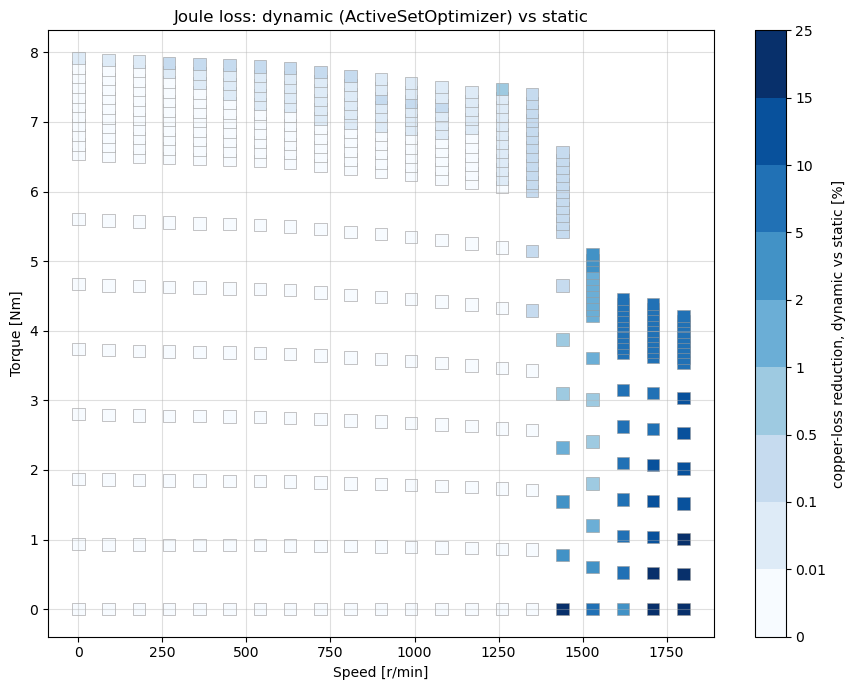

In [12]:
# Joule-loss difference: dynamic minus static, cell-by-cell -- valid because both grids
# were solved against the EXACT SAME 2D torque-target array (grid_torq_neural) and the SAME
# omega axis, and grid_joule_loss is the same physical quantity for both (cycle-averaged sum of
# squared PHASE current, see grid.py's _joule_loss_static/_trajectory_waveforms -- not a
# mean-then-squared proxy that would bias dynamic mode low relative to static).
rpm_vec = vec_omega * const_mech_speed
omega_2d = np.broadcast_to(rpm_vec[None, :], (N_TORQ, N_OMEGA))
torq_2d = grid_torq_neural  # identical array fed to both calculate_grid calls above

from matplotlib.colors import BoundaryNorm, SymLogNorm

joule_static = grid_static["grid_joule_loss"]
joule_dyn = grid_dynamic_old["grid_joule_loss"]
with np.errstate(divide="ignore", invalid="ignore"):
    joule_pct = 100.0 * (joule_dyn - joule_static) / joule_static  # relative to static [%]
both = np.isfinite(joule_pct)  # solved in BOTH modes; failed/skipped cells stay empty

# Same points as the region maps (each grid point at its own speed and torque target), colored by
# the relative difference on a log scale -- differences span ~0.05 % (current limit, low speed) to
# ~20 % (field weakening). Dynamic should never need more copper loss than static (a constant
# trajectory is a valid dynamic solution), so normally the REDUCTION is shown in discrete steps
# (each color = one labelled range; below 0.01 % = solver precision shows as white); if any cell is
# worse in dynamic mode, the plot falls back to a two-sided red/blue scale so that cell stays visible.
pct = joule_pct[both]
size = 80 if max(N_TORQ, N_OMEGA) > 10 else 600  # smaller squares for the dense full grid
fig, ax = plt.subplots(figsize=(9, 7))
if np.any(both) and np.nanmax(pct) <= 0.01:
    reduction = np.clip(-pct, 0.0, None)
    bounds = [0, 0.01, 0.1, 0.5, 1, 2, 5, 10, 15, max(25, int(np.ceil(reduction.max())))]
    cmap = plt.get_cmap("Blues", len(bounds) - 1)
    sc = ax.scatter(omega_2d[both], torq_2d[both], c=reduction, cmap=cmap,
                    norm=BoundaryNorm(bounds, cmap.N),
                    s=size, marker="s", edgecolors="0.6", linewidths=0.4)
    cbar = fig.colorbar(sc, ax=ax, ticks=bounds, spacing="uniform",
                        label="copper-loss reduction, dynamic vs static [%]")
    cbar.ax.set_yticklabels([f"{b:g}" for b in bounds])
else:
    vmax = max(float(np.nanmax(np.abs(pct))), 0.1) if np.any(both) else 1.0
    sc = ax.scatter(omega_2d[both], torq_2d[both], c=pct, cmap="RdBu_r",
                    norm=SymLogNorm(linthresh=0.01, linscale=0.5, vmin=-vmax, vmax=vmax, base=10),
                    s=size, marker="s", edgecolors="0.6", linewidths=0.4)
    fig.colorbar(sc, ax=ax, label="Joule-loss proxy: (dynamic $-$ static) / static [%]")
ax.set_xlabel("Speed [r/min]"); ax.set_ylabel("Torque [Nm]")
ax.set_title("Joule loss: dynamic (ActiveSetOptimizer) vs static")
ax.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

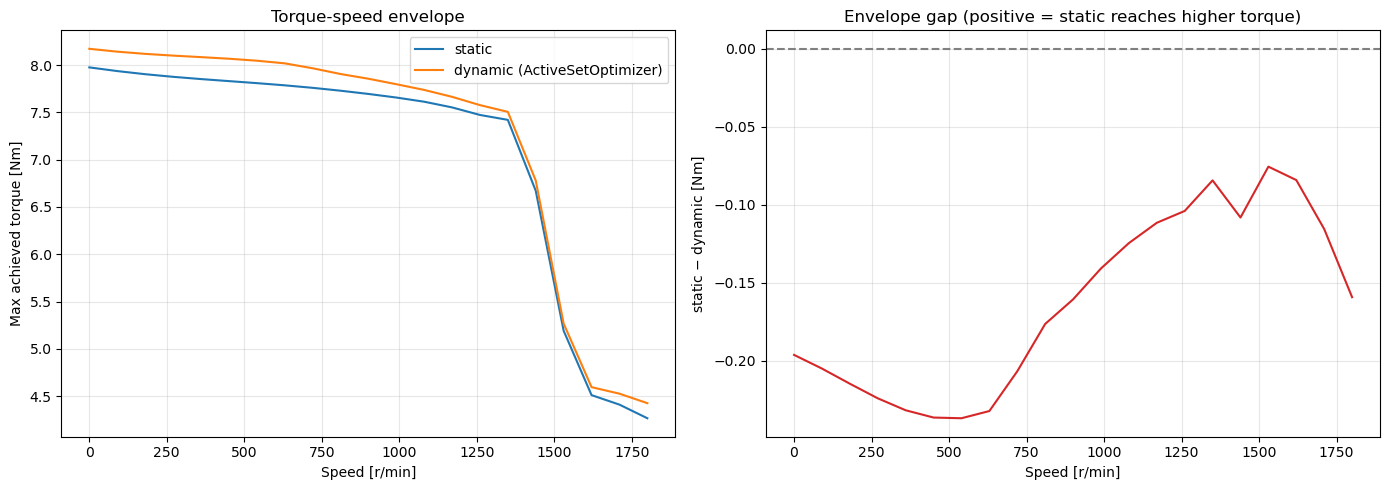

In [9]:
# Max achieved torque comparison -- uses tmax_static_row/tmax_old_row computed directly in the
# probing cell above (exact per-row values), not calculate_grid's own internal re-probe.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot(rpm_vec, tmax_static_row, label="static", color="tab:blue")
ax1.plot(rpm_vec, tmax_old_row, label="dynamic (ActiveSetOptimizer)", color="tab:orange")
ax1.set_xlabel("Speed [r/min]"); ax1.set_ylabel("Max achieved torque [Nm]")
ax1.set_title("Torque-speed envelope"); ax1.legend(); ax1.grid(alpha=0.3)

ax2.plot(rpm_vec, tmax_static_row - tmax_old_row, color="tab:red")
ax2.axhline(0.0, color="gray", ls="--")
ax2.set_xlabel("Speed [r/min]"); ax2.set_ylabel("static $-$ dynamic [Nm]")
ax2.set_title("Envelope gap (positive = static reaches higher torque)")
ax2.grid(alpha=0.3)
plt.tight_layout()
plt.show()

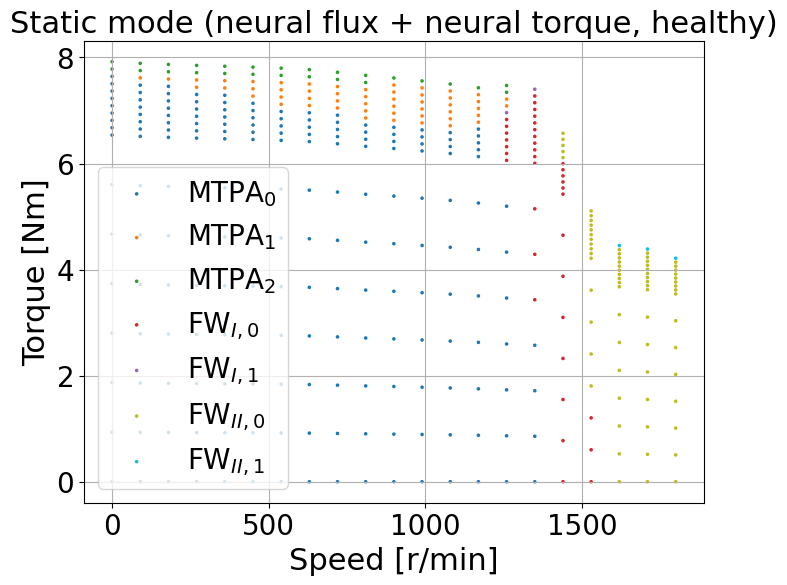

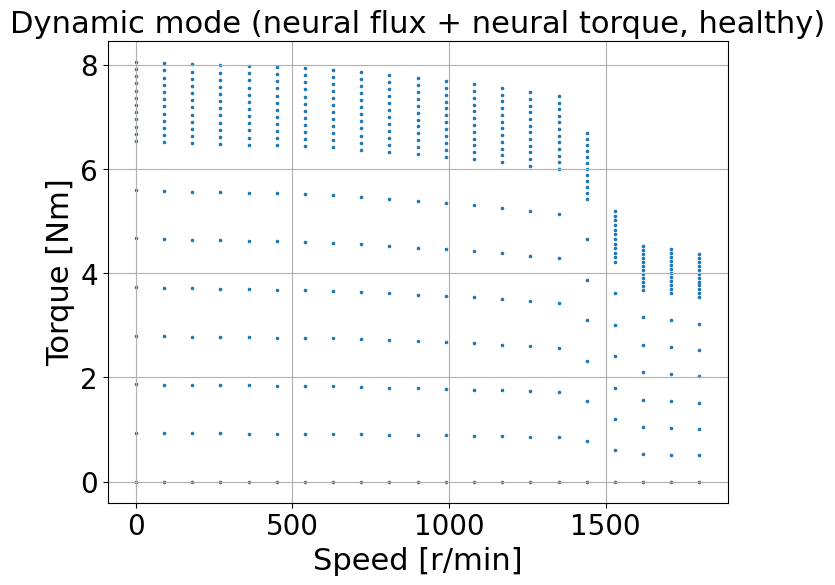

In [10]:
plot_grid_segments(grid_to_data(grid_static, k_skip=1), title="Static mode (neural flux + neural torque, healthy)", override_torq_2d=torq_2d)
# Dynamic map WITHOUT the MTPA/FW segment distinction (segments come from peak counting, defined for
# a constant current only): every solved grid point in one color, same layout as the static map.
from current_setpoints.utils.plotting import PlotConfig

solved_dyn = np.isfinite(grid_dynamic_old["grid_joule_loss"])  # converged cells only
with plt.rc_context(PlotConfig.get_rc_params()):
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.set_title("Dynamic mode (neural flux + neural torque, healthy)")
    ax.set_xlabel("Speed [r/min]")
    ax.set_ylabel("Torque [Nm]")
    ax.scatter(omega_2d[solved_dyn], torq_2d[solved_dyn], s=10, c="tab:blue", marker=".")
    ax.grid(True)
    plt.show()